# 01 - Exploratory Data Analysis (EDA)

This notebook covers:
1. Loading dataset and basic statistics
2. Target variable distribution before and after log1p transformation
3. Missing values analysis and domain meaning
4. Known outliers inspection (GrLivArea vs SalePrice)


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append("..")
from src.ames.data import load_raw_data, remove_known_outliers, get_feature_target_split
from src.ames.config import FIGURES_DIR

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## 1. Load Data

In [2]:
df = load_raw_data()
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 2. Target Variable Analysis (SalePrice)

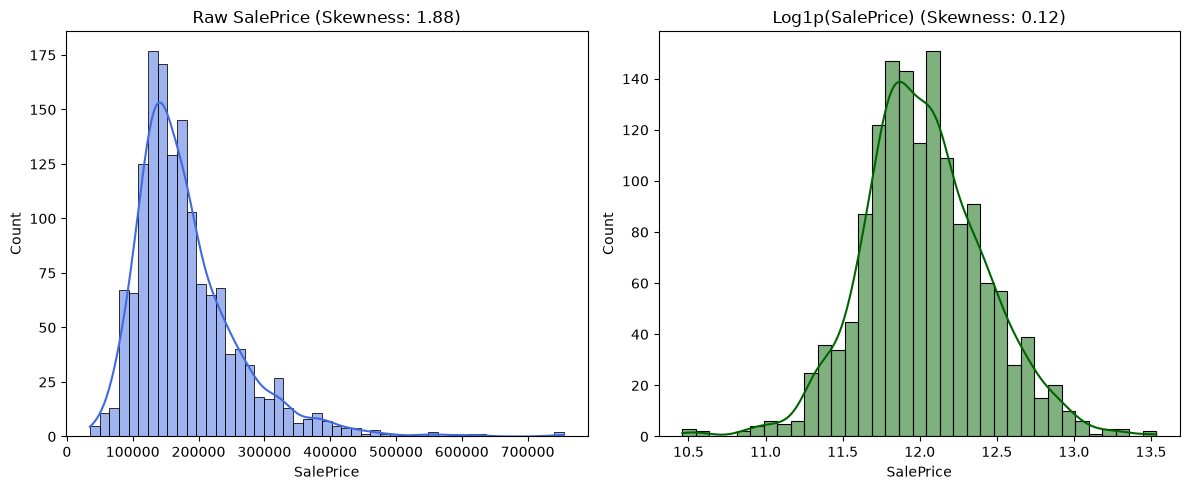

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
raw_skew = df["SalePrice"].skew()
log_skew = np.log1p(df["SalePrice"]).skew()

sns.histplot(df["SalePrice"], kde=True, ax=axes[0], color="royalblue")
axes[0].set_title(f"Raw SalePrice (Skewness: {raw_skew:.2f})")

sns.histplot(np.log1p(df["SalePrice"]), kde=True, ax=axes[1], color="darkgreen")
axes[1].set_title(f"Log1p(SalePrice) (Skewness: {log_skew:.2f})")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "target_distribution.png", dpi=300)
plt.show()

## 3. Missing Values Inspection

In [4]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({"Count": missing, "Percentage": missing_pct})
missing_df

,Count,Percentage
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageType,81,5.547945
GarageYrBlt,81,5.547945
GarageFinish,81,5.547945


C:\Users\achir\AppData\Local\Temp\ipykernel_1568\2364532197.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=missing_df.index[:15], y=missing_df["Percentage"][:15], palette="magma")


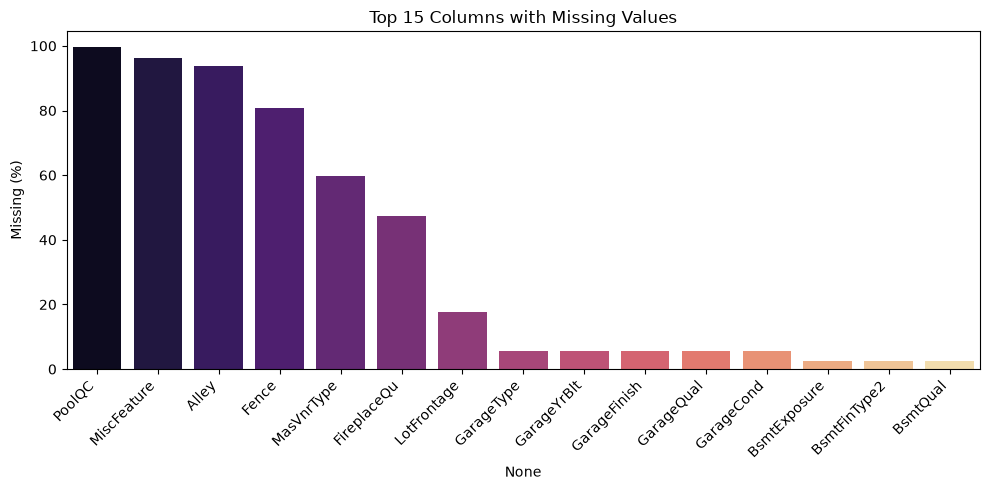

In [5]:
plt.figure(figsize=(10, 5))
sns.barplot(x=missing_df.index[:15], y=missing_df["Percentage"][:15], palette="magma")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Missing (%)")
plt.title("Top 15 Columns with Missing Values")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "missing_values.png", dpi=300)
plt.show()

## 4. Known Outliers (GrLivArea > 4000 & SalePrice < 300,000)

In [6]:
outliers = df[(df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000)]
outliers[["Id", "GrLivArea", "SalePrice"]]

,Id,GrLivArea,SalePrice
523,524,4676,184750
1298,1299,5642,160000


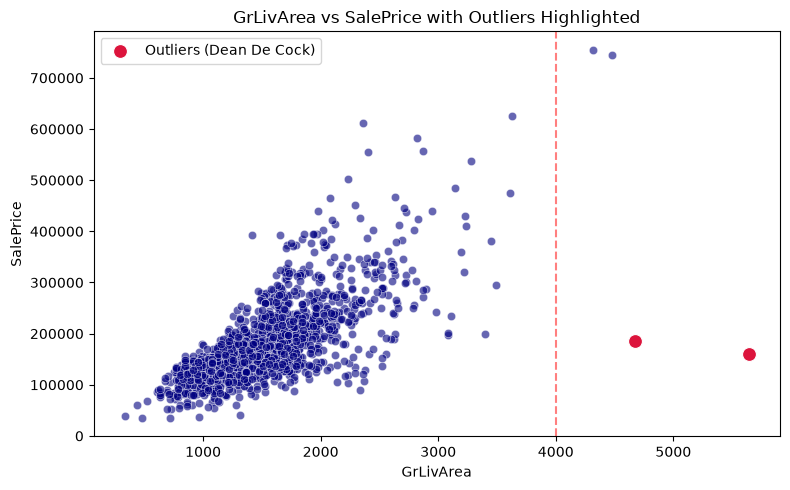

In [7]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="GrLivArea", y="SalePrice", alpha=0.6, color="navy")
sns.scatterplot(data=outliers, x="GrLivArea", y="SalePrice", color="crimson", s=100, label="Outliers (Dean De Cock)")
plt.axvline(4000, color="red", linestyle="--", alpha=0.5)
plt.title("GrLivArea vs SalePrice with Outliers Highlighted")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "outliers_scatter.png", dpi=300)
plt.show()